In [ ]:
# ============================================================
# CELL 1 — CONNECT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("=" * 70)
print("GOOGLE DRIVE CONNECTED")
print("=" * 70)

Mounted at /content/drive
GOOGLE DRIVE CONNECTED


In [ ]:
# ============================================================
# CELL 2 — LOAD FINAL 4,386-IMAGE K-MEANS DATASET
# ============================================================

import pandas as pd
import numpy as np
import os

# ------------------------------------------------------------
# PATH
# ------------------------------------------------------------

CSV_PATH = "/content/drive/MyDrive/cherry_final_kmeans_4386.csv"

# ------------------------------------------------------------
# CHECK FILE
# ------------------------------------------------------------

print("=" * 70)
print("LOADING FINAL CHERRY DATASET")
print("=" * 70)

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"Dataset not found:\n{CSV_PATH}"
    )

print("\n✅ Dataset file found:")
print(CSV_PATH)

# ------------------------------------------------------------
# LOAD DATASET
# ------------------------------------------------------------

df = pd.read_csv(CSV_PATH)

print("\n" + "=" * 70)
print("DATASET LOADED")
print("=" * 70)

print(f"\nTotal images : {len(df)}")

print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# BASIC VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS / STAGE DISTRIBUTION")
print("=" * 70)

print(df["stage"].value_counts())

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

print(df.isnull().sum())

print("\n" + "=" * 70)
print("DUPLICATE IMAGE PATHS")
print("=" * 70)

print(df["image_path"].duplicated().sum())

# ------------------------------------------------------------
# EXPECTED DISTRIBUTION
# ------------------------------------------------------------

expected_counts = {
    "Healthy": 2282,
    "Early": 1156,
    "Moderate": 834,
    "Severe": 114
}

actual_counts = df["stage"].value_counts().to_dict()

print("\n" + "=" * 70)
print("FINAL VERIFICATION")
print("=" * 70)

verification_passed = True

if len(df) != 4386:
    print("❌ Total image count mismatch")
    verification_passed = False
else:
    print("✅ Total images : 4386")

for stage, expected in expected_counts.items():

    actual = actual_counts.get(stage, 0)

    if actual == expected:
        print(f"✅ {stage:<10}: {actual}")
    else:
        print(
            f"❌ {stage:<10}: "
            f"expected {expected}, found {actual}"
        )
        verification_passed = False

if df.isnull().sum().sum() != 0:
    print("❌ Missing values detected")
    verification_passed = False
else:
    print("✅ Missing values : 0")

if df["image_path"].duplicated().sum() != 0:
    print("❌ Duplicate image paths detected")
    verification_passed = False
else:
    print("✅ Duplicate image paths : 0")

# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)

if verification_passed:
    print("✅ FINAL 4,386-IMAGE DATASET VERIFIED")
    print("✅ df IS READY FOR RESULTS ANALYSIS")
else:
    print("❌ DATASET VERIFICATION FAILED")

print("=" * 70)

LOADING FINAL CHERRY DATASET

✅ Dataset file found:
/content/drive/MyDrive/cherry_final_kmeans_4386.csv

DATASET LOADED

Total images : 4386

Columns:
['image_path', 'filename', 'class', 'coverage', 'patches', 'largest_patch', 'avg_patch', 'brightness', 'stage']

CLASS / STAGE DISTRIBUTION
stage
Healthy     2282
Early       1156
Moderate     834
Severe       114
Name: count, dtype: int64

MISSING VALUES
image_path       0
filename         0
class            0
coverage         0
patches          0
largest_patch    0
avg_patch        0
brightness       0
stage            0
dtype: int64

DUPLICATE IMAGE PATHS
0

FINAL VERIFICATION
✅ Total images : 4386
✅ Healthy   : 2282
✅ Early     : 1156
✅ Moderate  : 834
✅ Severe    : 114
✅ Missing values : 0
✅ Duplicate image paths : 0

✅ FINAL 4,386-IMAGE DATASET VERIFIED
✅ df IS READY FOR RESULTS ANALYSIS


In [ ]:
# ============================================================
# CELL 3 — DISEASE FEATURE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("CHERRY DISEASE FEATURE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# FEATURES
# ------------------------------------------------------------

feature_columns = [
    "coverage",
    "patches",
    "largest_patch",
    "avg_patch",
    "brightness"
]

print("\nFeatures being analyzed:")
for feature in feature_columns:
    print(" -", feature)

# ------------------------------------------------------------
# SPLIT ORIGINAL CLASSES
# ------------------------------------------------------------

healthy_df = df[df["class"] == "Healthy"].copy()
diseased_df = df[df["class"] == "Powdery_mildew"].copy()

print("\n" + "=" * 70)
print("CLASS COUNTS")
print("=" * 70)

print(f"\nHealthy images        : {len(healthy_df)}")
print(f"Powdery mildew images : {len(diseased_df)}")

# ------------------------------------------------------------
# FEATURE STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HEALTHY FEATURE STATISTICS")
print("=" * 70)

healthy_stats = healthy_df[feature_columns].describe().T[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]

print(healthy_stats.round(4))

print("\n" + "=" * 70)
print("POWDERY MILDEW FEATURE STATISTICS")
print("=" * 70)

diseased_stats = diseased_df[feature_columns].describe().T[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]

print(diseased_stats.round(4))

# ------------------------------------------------------------
# CLASS COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HEALTHY vs POWDERY MILDEW — MEAN COMPARISON")
print("=" * 70)

comparison = pd.DataFrame({
    "Healthy Mean": healthy_df[feature_columns].mean(),
    "Powdery Mildew Mean": diseased_df[feature_columns].mean()
})

comparison["Absolute Difference"] = (
    comparison["Powdery Mildew Mean"]
    - comparison["Healthy Mean"]
).abs()

print(comparison.round(4))

# ------------------------------------------------------------
# MEDIAN COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HEALTHY vs POWDERY MILDEW — MEDIAN COMPARISON")
print("=" * 70)

median_comparison = pd.DataFrame({
    "Healthy Median": healthy_df[feature_columns].median(),
    "Powdery Mildew Median": diseased_df[feature_columns].median()
})

print(median_comparison.round(4))

print("\n" + "=" * 70)
print("✅ DISEASE FEATURE ANALYSIS COMPLETE")
print("=" * 70)

CHERRY DISEASE FEATURE ANALYSIS

Features being analyzed:
 - coverage
 - patches
 - largest_patch
 - avg_patch
 - brightness

CLASS COUNTS

Healthy images        : 2282
Powdery mildew images : 2104

HEALTHY FEATURE STATISTICS
                count        mean         std       min         25%  \
coverage       2282.0     55.3691     15.9871    4.7456     47.6518   
patches        2282.0     19.3655     13.5273    1.0000      9.0000   
largest_patch  2282.0  25580.9106  13311.0837  196.0000  14543.7500   
avg_patch      2282.0   4166.8149   7072.8864   51.8571    855.5833   
brightness     2282.0    153.7766     20.8166  102.5042    137.3266   

                      50%         75%         max  
coverage          56.8054     65.4740     96.5143  
patches           17.0000     27.0000     88.0000  
largest_patch  27159.0000  36245.5000  55482.0000  
avg_patch       1728.4500   3965.4286  45033.0000  
brightness       153.2482    166.5787    216.6389  

POWDERY MILDEW FEATURE STATISTICS


GENERATING HEALTHY vs POWDERY MILDEW FEATURE PLOTS


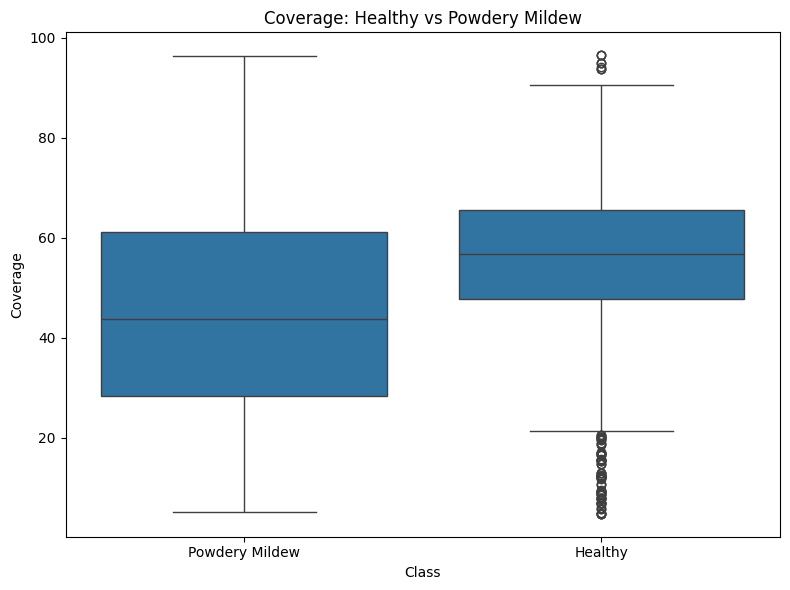

✅ Saved: /content/drive/MyDrive/Cherry_Results/healthy_vs_powdery_coverage.png


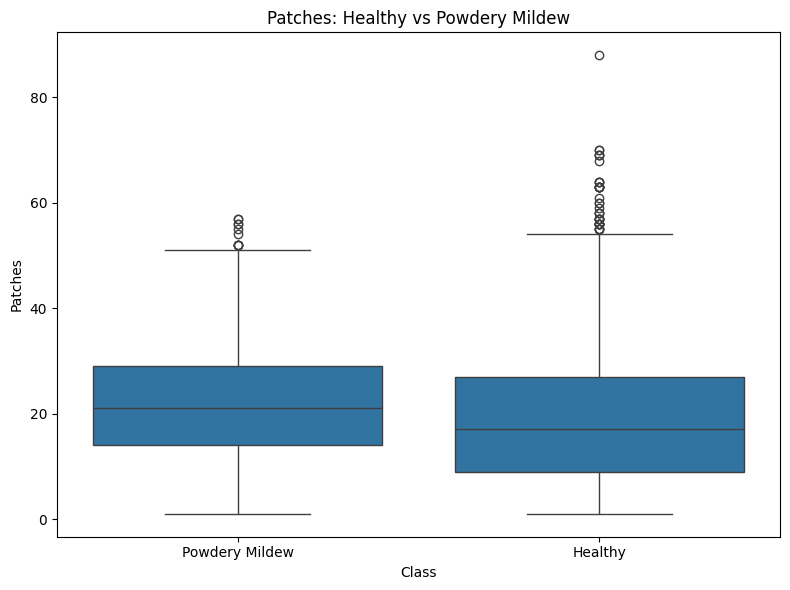

✅ Saved: /content/drive/MyDrive/Cherry_Results/healthy_vs_powdery_patches.png


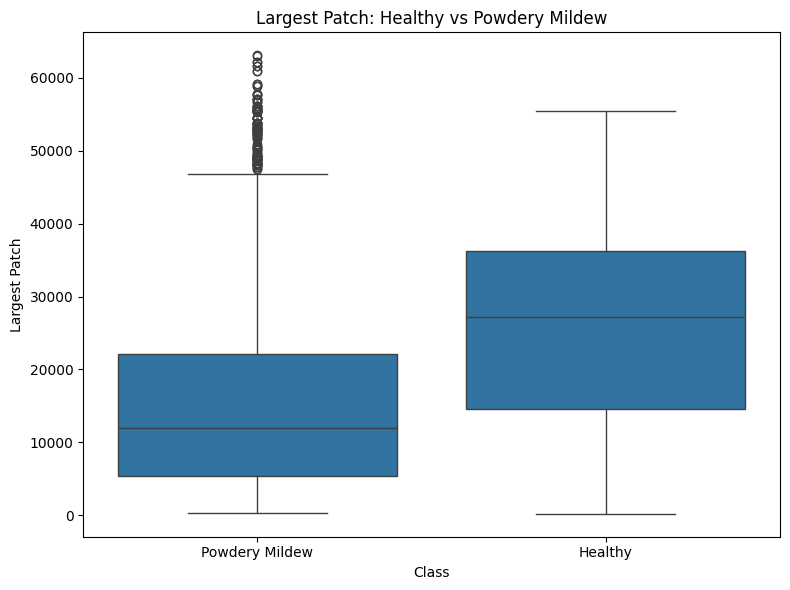

✅ Saved: /content/drive/MyDrive/Cherry_Results/healthy_vs_powdery_largest_patch.png


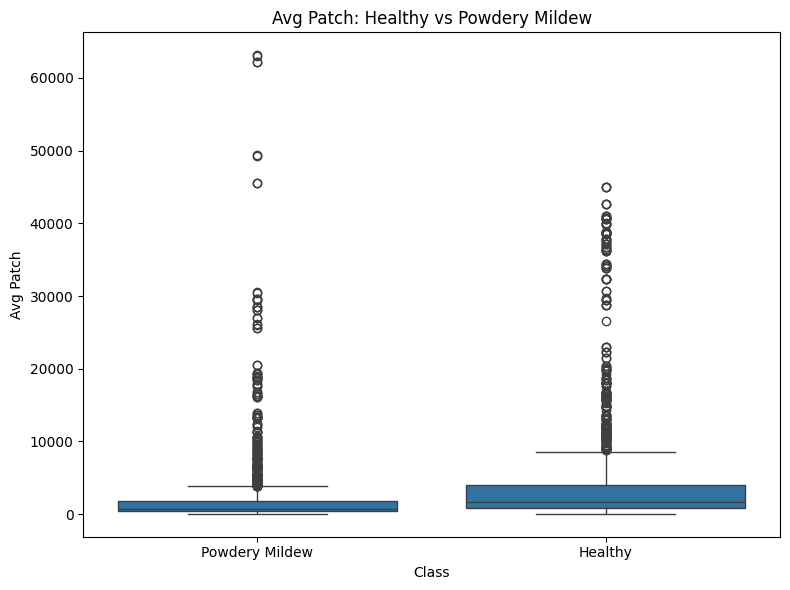

✅ Saved: /content/drive/MyDrive/Cherry_Results/healthy_vs_powdery_avg_patch.png


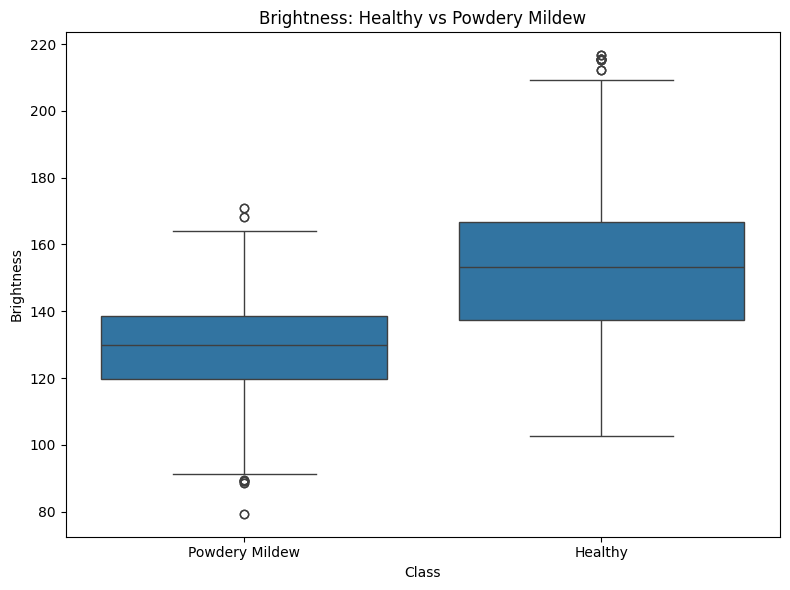

✅ Saved: /content/drive/MyDrive/Cherry_Results/healthy_vs_powdery_brightness.png

✅ ALL FEATURE DISTRIBUTION FIGURES GENERATED

Output directory:
/content/drive/MyDrive/Cherry_Results


In [ ]:
# ============================================================
# CELL 4 — HEALTHY vs POWDERY MILDEW FEATURE DISTRIBUTIONS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import os

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/Cherry_Results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# PREPARE DATA
# ------------------------------------------------------------

plot_df = df[["class"] + feature_columns].copy()

# Clean class names for figure labels
plot_df["class"] = plot_df["class"].replace({
    "Powdery_mildew": "Powdery Mildew"
})

print("=" * 70)
print("GENERATING HEALTHY vs POWDERY MILDEW FEATURE PLOTS")
print("=" * 70)

# ------------------------------------------------------------
# GENERATE INDIVIDUAL BOXPLOTS
# ------------------------------------------------------------

for feature in feature_columns:

    plt.figure(figsize=(8, 6))

    sns.boxplot(
        data=plot_df,
        x="class",
        y=feature
    )

    plt.title(
        f"{feature.replace('_', ' ').title()}: "
        "Healthy vs Powdery Mildew"
    )

    plt.xlabel("Class")
    plt.ylabel(feature.replace("_", " ").title())

    plt.tight_layout()

    output_path = os.path.join(
        RESULTS_DIR,
        f"healthy_vs_powdery_{feature}.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"✅ Saved: {output_path}")

print("\n" + "=" * 70)
print("✅ ALL FEATURE DISTRIBUTION FIGURES GENERATED")
print("=" * 70)

print("\nOutput directory:")
print(RESULTS_DIR)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

print("=" * 70)
print("GOOGLE DRIVE CONNECTED")
print("=" * 70)

Mounted at /content/drive
GOOGLE DRIVE CONNECTED


In [ ]:
# ============================================================
# DISEASE FEATURE VISUALIZATIONS
# COVERAGE, NUMBER OF PATCHES, LARGEST PATCH
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("GENERATING DISEASE FEATURE VISUALIZATIONS")
print("=" * 70)

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = "/content/drive/MyDrive/Cherry_Results_Feature_Analysis"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# PREPARE DATA
# ------------------------------------------------------------

healthy_df = df[df["stage"] == "Healthy"].copy()
diseased_df = df[df["stage"] != "Healthy"].copy()

print(f"Healthy images        : {len(healthy_df)}")
print(f"Diseased images       : {len(diseased_df)}")

# ============================================================
# 1. DISEASE COVERAGE
# ============================================================

plt.figure(figsize=(10, 7))

sns.boxplot(
    data=df,
    x="class",
    y="coverage"
)

plt.title("Disease Coverage: Healthy vs Powdery Mildew")
plt.xlabel("Class")
plt.ylabel("Disease Coverage (%)")
plt.tight_layout()

coverage_path = os.path.join(
    output_dir,
    "coverage_healthy_vs_powdery.png"
)

plt.savefig(coverage_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Coverage plot saved:")
print(coverage_path)

# ============================================================
# 2. NUMBER OF DISEASE PATCHES
# ============================================================

plt.figure(figsize=(10, 7))

sns.boxplot(
    data=df,
    x="class",
    y="patches"
)

plt.title("Disease Patches: Healthy vs Powdery Mildew")
plt.xlabel("Class")
plt.ylabel("Number of Disease Patches")
plt.tight_layout()

patches_path = os.path.join(
    output_dir,
    "patches_healthy_vs_powdery.png"
)

plt.savefig(patches_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Patches plot saved:")
print(patches_path)

# ============================================================
# 3. LARGEST DISEASE PATCH
# ============================================================

plt.figure(figsize=(10, 7))

sns.boxplot(
    data=df,
    x="class",
    y="largest_patch"
)

plt.title("Largest Disease Patch: Healthy vs Powdery Mildew")
plt.xlabel("Class")
plt.ylabel("Largest Patch Size (pixels)")
plt.tight_layout()

largest_patch_path = os.path.join(
    output_dir,
    "largest_patch_healthy_vs_powdery.png"
)

plt.savefig(
    largest_patch_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"✅ Largest-patch plot saved:")
print(largest_patch_path)

# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("DISEASE FEATURE VISUALIZATIONS COMPLETE")
print("=" * 70)

print("\nSaved files:")
print("1.", coverage_path)
print("2.", patches_path)
print("3.", largest_patch_path)

print("\n✅ ALL THREE FEATURE VISUALIZATIONS SAVED TO GOOGLE DRIVE")

GENERATING DISEASE FEATURE VISUALIZATIONS


NameError: name 'df' is not defined

In [ ]:
# ============================================================
# RESTORE FINAL DATASET FOR RESULTS ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import os

print("=" * 70)
print("RESTORING FINAL CHERRY DATASET")
print("=" * 70)

DATASET_PATH = "/content/drive/MyDrive/cherry_final_kmeans_4386.csv"

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found:\n{DATASET_PATH}"
    )

df = pd.read_csv(DATASET_PATH)

print("\n✅ Dataset loaded")
print(f"Total images : {len(df)}")

print("\nColumns:")
print(df.columns.tolist())

print("\nStage distribution:")
print(df["stage"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\n" + "=" * 70)
print("✅ DF READY FOR RESULTS ANALYSIS")
print("=" * 70)

RESTORING FINAL CHERRY DATASET

✅ Dataset loaded
Total images : 4386

Columns:
['image_path', 'filename', 'class', 'coverage', 'patches', 'largest_patch', 'avg_patch', 'brightness', 'stage']

Stage distribution:
stage
Healthy     2282
Early       1156
Moderate     834
Severe       114
Name: count, dtype: int64

Missing values:
image_path       0
filename         0
class            0
coverage         0
patches          0
largest_patch    0
avg_patch        0
brightness       0
stage            0
dtype: int64

✅ DF READY FOR RESULTS ANALYSIS


GENERATING FEATURE VISUALIZATIONS

Healthy images        : 2282
Powdery mildew images : 2104

Generating: coverage


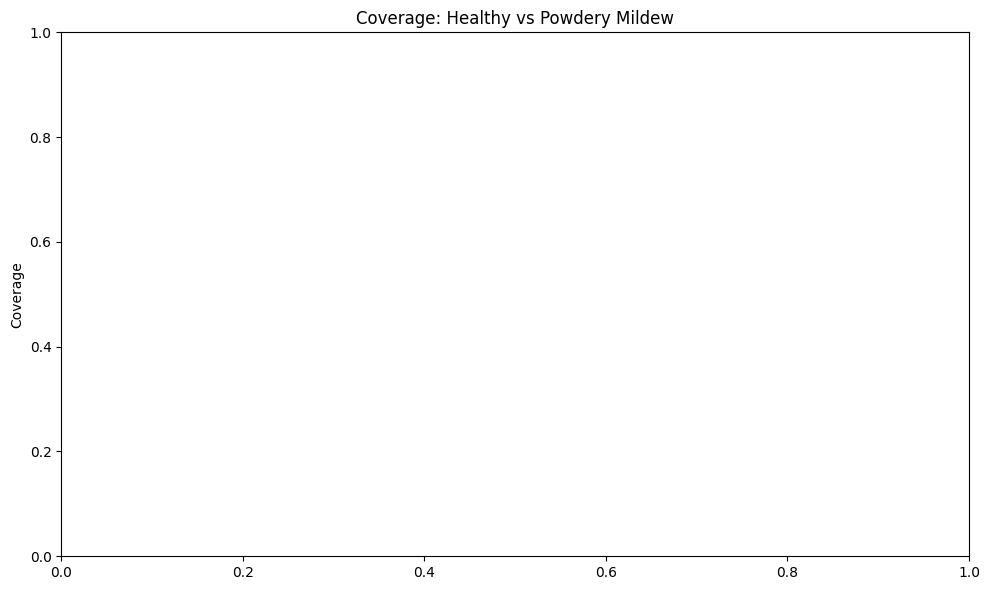

Saved: /content/drive/MyDrive/ResNet50_KMeans_Results/Feature_Analysis/healthy_vs_powdery_coverage.png

Generating: patches


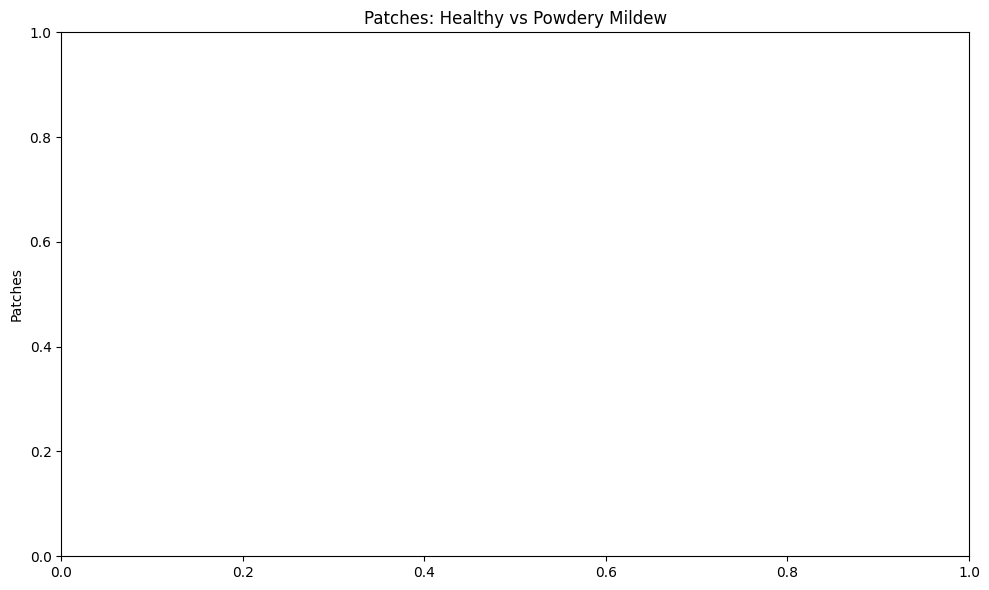

Saved: /content/drive/MyDrive/ResNet50_KMeans_Results/Feature_Analysis/healthy_vs_powdery_patches.png

Generating: largest_patch


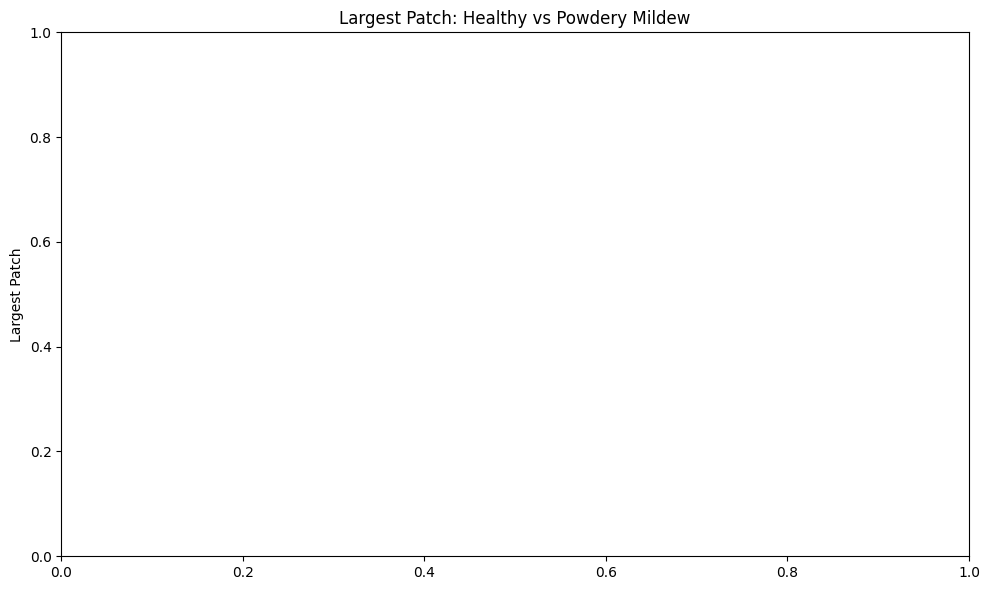

Saved: /content/drive/MyDrive/ResNet50_KMeans_Results/Feature_Analysis/healthy_vs_powdery_largest_patch.png

Generating: avg_patch


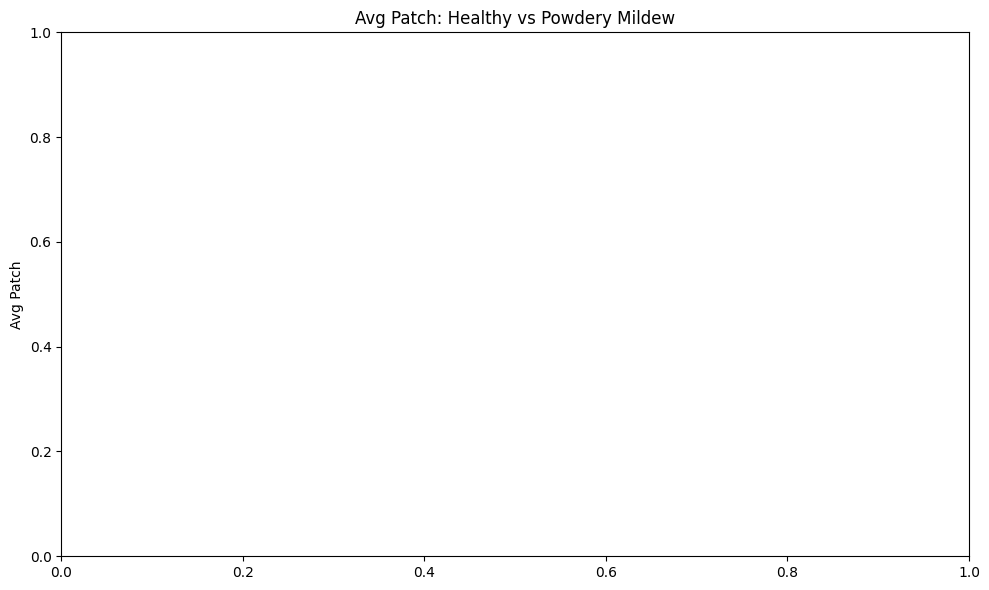

Saved: /content/drive/MyDrive/ResNet50_KMeans_Results/Feature_Analysis/healthy_vs_powdery_avg_patch.png

Generating: brightness


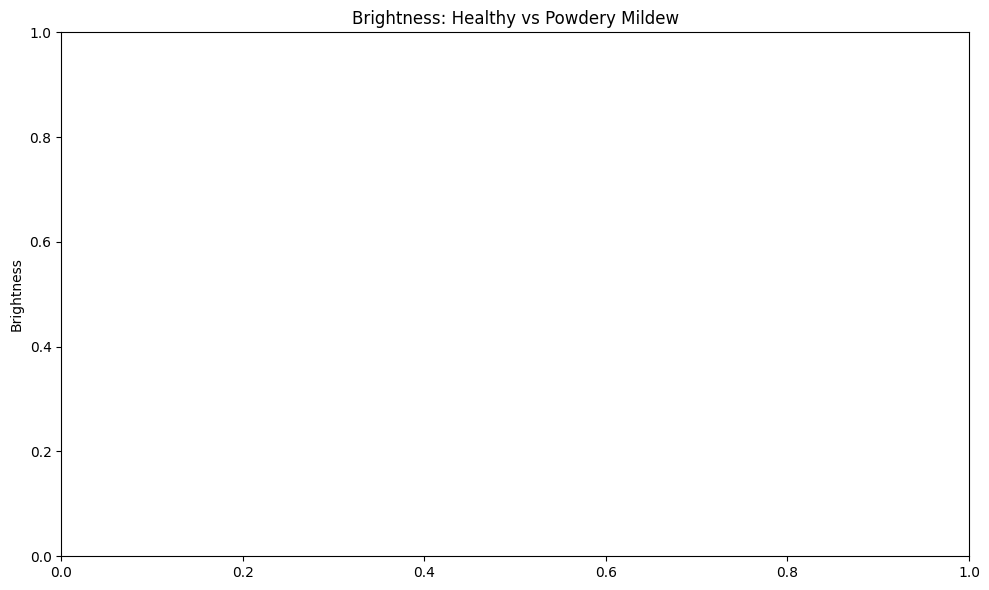

Saved: /content/drive/MyDrive/ResNet50_KMeans_Results/Feature_Analysis/healthy_vs_powdery_brightness.png

FEATURE VISUALIZATION COMPLETE

Output directory:
/content/drive/MyDrive/ResNet50_KMeans_Results/Feature_Analysis

Generated figures:
 - healthy_vs_powdery_coverage.png
 - healthy_vs_powdery_patches.png
 - healthy_vs_powdery_largest_patch.png
 - healthy_vs_powdery_avg_patch.png
 - healthy_vs_powdery_brightness.png

✅ ALL FEATURE VISUALIZATIONS SAVED


In [ ]:
# ============================================================
# DISEASE / IMAGE FEATURE VISUALIZATIONS
# FINAL CHERRY K-MEANS DATASET
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("GENERATING FEATURE VISUALIZATIONS")
print("=" * 70)

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

output_dir = "/content/drive/MyDrive/ResNet50_KMeans_Results/Feature_Analysis"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Create groups
# ------------------------------------------------------------

healthy_df = df[df["stage"] == "Healthy"].copy()
diseased_df = df[df["stage"] != "Healthy"].copy()

# Original disease class
powdery_df = df[df["class"].str.contains("Powdery_mildew", case=False, na=False)].copy()

print()
print("Healthy images        :", len(healthy_df))
print("Powdery mildew images :", len(powdery_df))

# ------------------------------------------------------------
# Features
# ------------------------------------------------------------

features = [
    "coverage",
    "patches",
    "largest_patch",
    "avg_patch",
    "brightness"
]

# ------------------------------------------------------------
# Generate individual boxplots
# ------------------------------------------------------------

for feature in features:

    print(f"\nGenerating: {feature}")

    plt.figure(figsize=(10, 6))

    plot_df = df[df["class"].isin(
        [
            "Cherry_(including_sour)___healthy",
            "Cherry_(including_sour)___Powdery_mildew"
        ]
    )].copy()

    plot_df["Class"] = plot_df["class"].map({
        "Cherry_(including_sour)___healthy": "Healthy",
        "Cherry_(including_sour)___Powdery_mildew": "Powdery Mildew"
    })

    sns.boxplot(
        data=plot_df,
        x="Class",
        y=feature
    )

    plt.title(
        f"{feature.replace('_', ' ').title()}: "
        "Healthy vs Powdery Mildew"
    )

    plt.xlabel("")
    plt.ylabel(feature.replace("_", " ").title())

    plt.tight_layout()

    save_path = os.path.join(
        output_dir,
        f"healthy_vs_powdery_{feature}.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", save_path)

# ------------------------------------------------------------
# Complete
# ------------------------------------------------------------

print()
print("=" * 70)
print("FEATURE VISUALIZATION COMPLETE")
print("=" * 70)
print()
print("Output directory:")
print(output_dir)
print()
print("Generated figures:")
for feature in features:
    print(f" - healthy_vs_powdery_{feature}.png")

print()
print("✅ ALL FEATURE VISUALIZATIONS SAVED")

GENERATING DISEASE FEATURE VISUALIZATIONS

Healthy images : 2282
Diseased images: 2104

FEATURE DATA VERIFICATION

coverage
----------------------------------------
Healthy:
  Count : 2282
  Min   : 4.745604998172211
  Max   : 96.51431620131602
  Mean  : 55.369056179904256
Diseased:
  Count : 2104
  Min   : 5.0820451843044
  Max   : 96.4171670409925
  Mean  : 45.705386203124654

patches
----------------------------------------
Healthy:
  Count : 2282
  Min   : 1
  Max   : 88
  Mean  : 19.36546888694128
Diseased:
  Count : 2104
  Min   : 1
  Max   : 57
  Mean  : 22.049429657794676

largest_patch
----------------------------------------
Healthy:
  Count : 2282
  Min   : 196.0
  Max   : 55482.0
  Mean  : 25580.91060473269
Diseased:
  Count : 2104
  Min   : 322.0
  Max   : 63106.0
  Mean  : 15926.73716730038

avg_patch
----------------------------------------
Healthy:
  Count : 2282
  Min   : 51.85714285714285
  Max   : 45033.0
  Mean  : 4166.814883331697
Diseased:
  Count : 2104
  Min   :

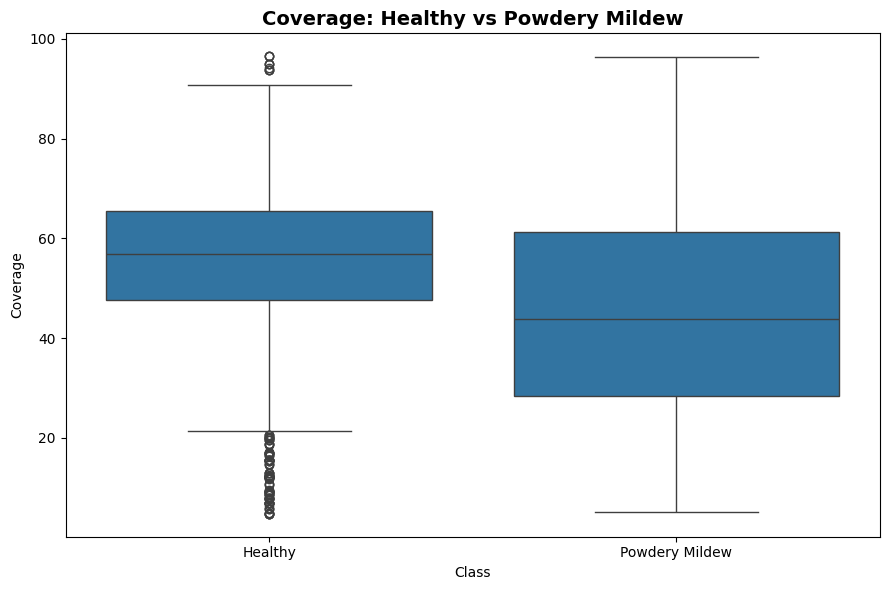

Saved: /content/drive/MyDrive/Cherry_Results/Disease_Feature_Analysis/healthy_vs_powdery_coverage.png


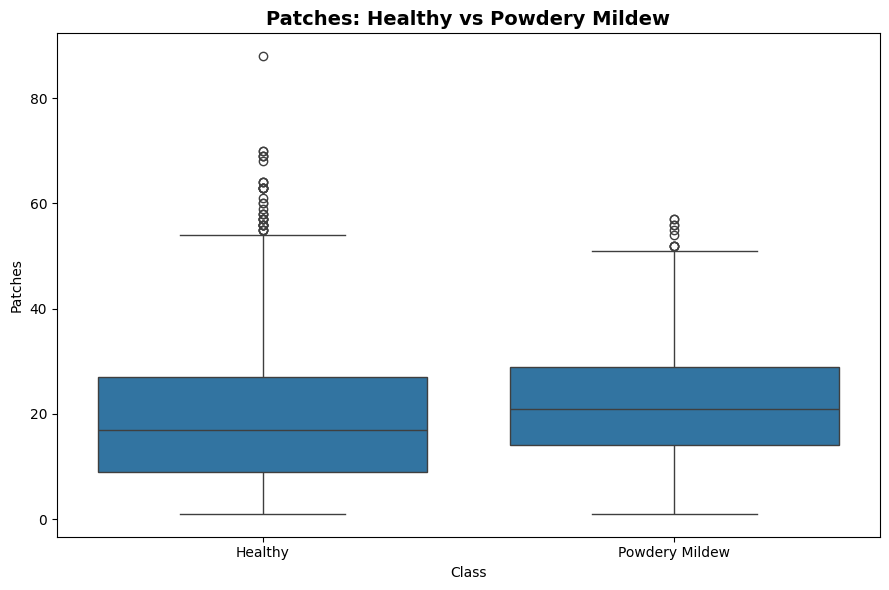

Saved: /content/drive/MyDrive/Cherry_Results/Disease_Feature_Analysis/healthy_vs_powdery_patches.png


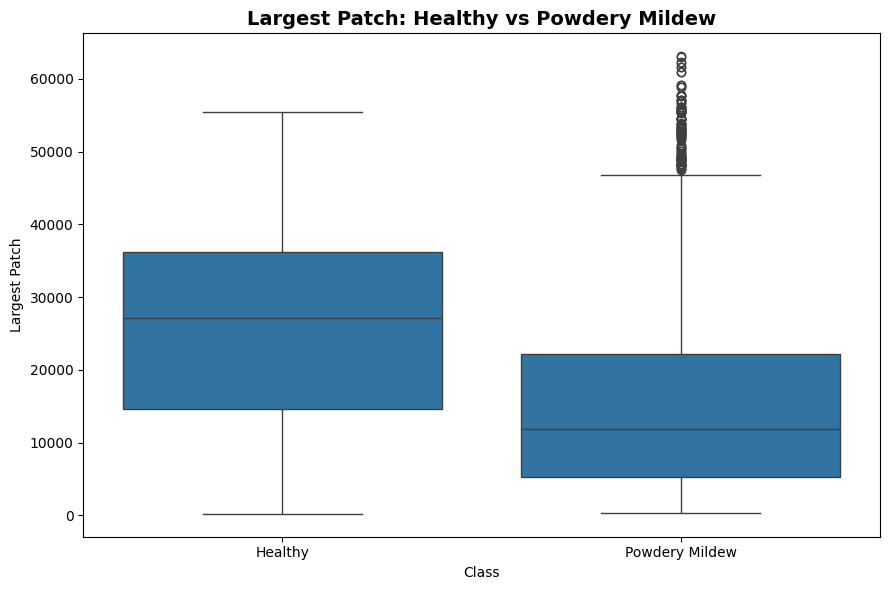

Saved: /content/drive/MyDrive/Cherry_Results/Disease_Feature_Analysis/healthy_vs_powdery_largest_patch.png


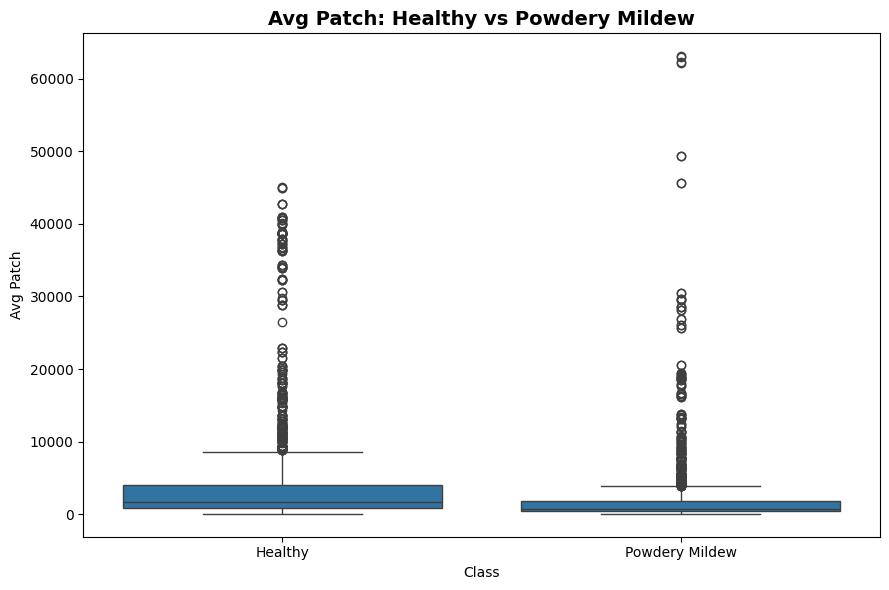

Saved: /content/drive/MyDrive/Cherry_Results/Disease_Feature_Analysis/healthy_vs_powdery_avg_patch.png


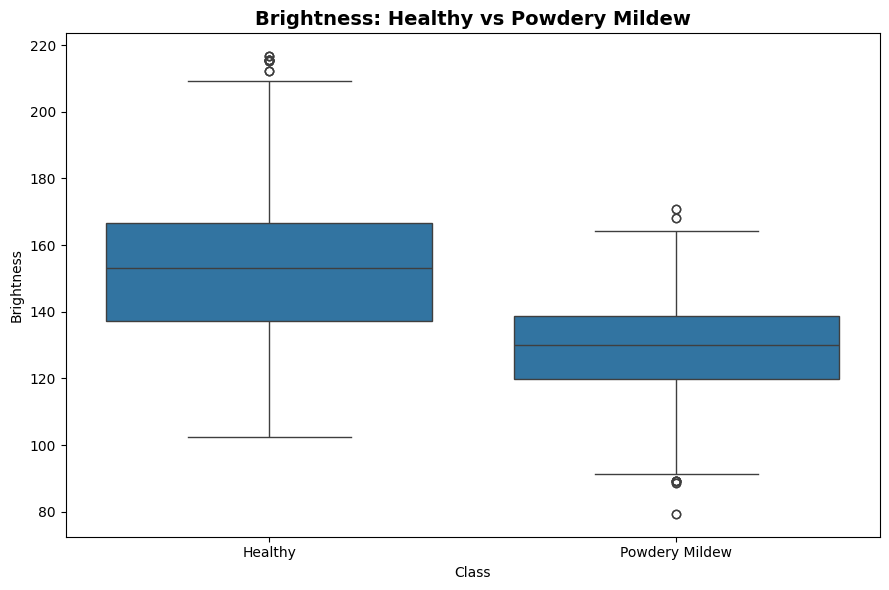

Saved: /content/drive/MyDrive/Cherry_Results/Disease_Feature_Analysis/healthy_vs_powdery_brightness.png

CREATING MEAN COMPARISON

         Feature       Healthy  Powdery Mildew
0       coverage     55.369056       45.705386
1        patches     19.365469       22.049430
2  largest_patch  25580.910605    15926.737167
3      avg_patch   4166.814883     2129.797979
4     brightness    153.776575      128.932606


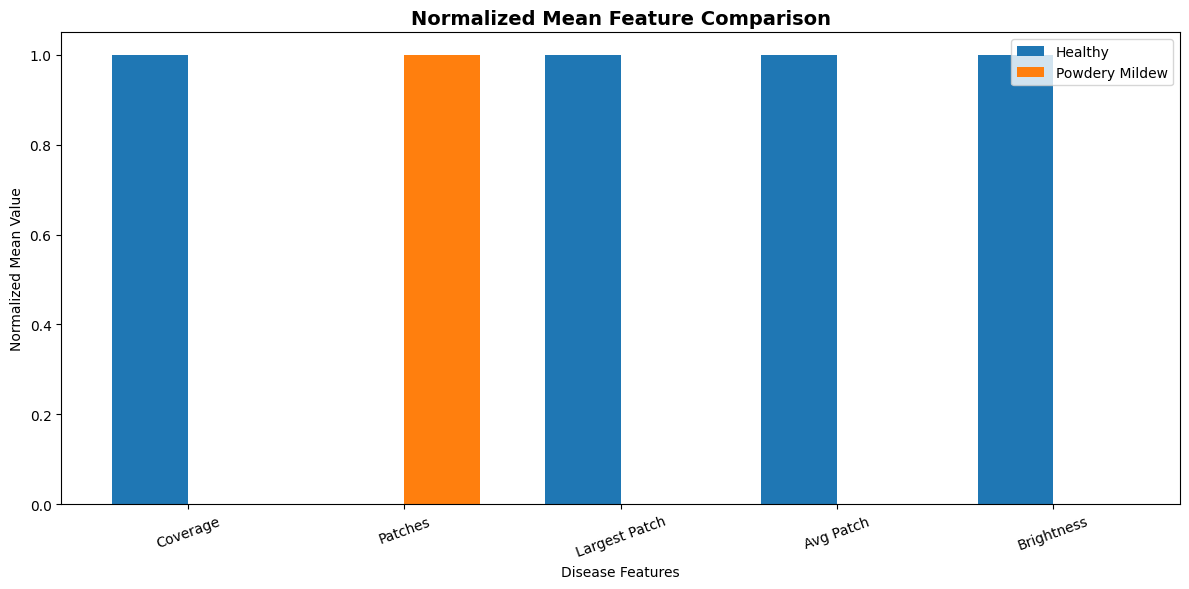


Saved: /content/drive/MyDrive/Cherry_Results/Disease_Feature_Analysis/normalized_mean_feature_comparison.png

✅ DISEASE FEATURE VISUALIZATION COMPLETE

Output directory:
/content/drive/MyDrive/Cherry_Results/Disease_Feature_Analysis


In [5]:
# ============================================================
# DISEASE FEATURE VISUALIZATIONS — FINAL RESULTS
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

print("=" * 70)
print("GENERATING DISEASE FEATURE VISUALIZATIONS")
print("=" * 70)

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = "/content/drive/MyDrive/Cherry_Results/Disease_Feature_Analysis"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# CREATE HEALTHY / DISEASED DATASETS
# ------------------------------------------------------------

healthy_df = df[df["stage"] == "Healthy"].copy()
diseased_df = df[df["stage"] != "Healthy"].copy()

print()
print("Healthy images :", len(healthy_df))
print("Diseased images:", len(diseased_df))

# ------------------------------------------------------------
# FEATURES
# ------------------------------------------------------------

features = [
    "coverage",
    "patches",
    "largest_patch",
    "avg_patch",
    "brightness"
]

# ------------------------------------------------------------
# VERIFY DATA BEFORE PLOTTING
# ------------------------------------------------------------

print()
print("=" * 70)
print("FEATURE DATA VERIFICATION")
print("=" * 70)

for feature in features:

    print()
    print(f"{feature}")
    print("-" * 40)

    print("Healthy:")
    print("  Count :", healthy_df[feature].count())
    print("  Min   :", healthy_df[feature].min())
    print("  Max   :", healthy_df[feature].max())
    print("  Mean  :", healthy_df[feature].mean())

    print("Diseased:")
    print("  Count :", diseased_df[feature].count())
    print("  Min   :", diseased_df[feature].min())
    print("  Max   :", diseased_df[feature].max())
    print("  Mean  :", diseased_df[feature].mean())

# ============================================================
# 1. BOX PLOTS
# ============================================================

print()
print("=" * 70)
print("CREATING BOX PLOTS")
print("=" * 70)

for feature in features:

    plt.figure(figsize=(9, 6))

    plot_df = pd.DataFrame({
        "Feature Value": pd.concat([
            healthy_df[feature],
            diseased_df[feature]
        ], ignore_index=True),

        "Class": (
            ["Healthy"] * len(healthy_df) +
            ["Powdery Mildew"] * len(diseased_df)
        )
    })

    sns.boxplot(
        data=plot_df,
        x="Class",
        y="Feature Value"
    )

    plt.title(
        f"{feature.replace('_', ' ').title()}: Healthy vs Powdery Mildew",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Class")
    plt.ylabel(feature.replace("_", " ").title())

    plt.tight_layout()

    save_path = os.path.join(
        output_dir,
        f"healthy_vs_powdery_{feature}.png"
    )

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Saved: {save_path}")

# ============================================================
# 2. MEAN COMPARISON
# ============================================================

print()
print("=" * 70)
print("CREATING MEAN COMPARISON")
print("=" * 70)

mean_values = pd.DataFrame({
    "Feature": features,
    "Healthy": [
        healthy_df[f].mean() for f in features
    ],
    "Powdery Mildew": [
        diseased_df[f].mean() for f in features
    ]
})

print()
print(mean_values)

# ------------------------------------------------------------
# Because features have very different scales, normalize
# only for visualization of relative differences.
# ------------------------------------------------------------

normalized = mean_values.copy()

for feature in features:

    values = [
        healthy_df[feature].mean(),
        diseased_df[feature].mean()
    ]

    min_val = min(values)
    max_val = max(values)

    if max_val != min_val:
        normalized.loc[
            normalized["Feature"] == feature,
            ["Healthy", "Powdery Mildew"]
        ] = [
            (values[0] - min_val) / (max_val - min_val),
            (values[1] - min_val) / (max_val - min_val)
        ]
    else:
        normalized.loc[
            normalized["Feature"] == feature,
            ["Healthy", "Powdery Mildew"]
        ] = 0

# ------------------------------------------------------------
# Plot normalized comparison
# ------------------------------------------------------------

x = np.arange(len(features))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    normalized["Healthy"],
    width,
    label="Healthy"
)

plt.bar(
    x + width / 2,
    normalized["Powdery Mildew"],
    width,
    label="Powdery Mildew"
)

plt.xticks(
    x,
    [f.replace("_", " ").title() for f in features],
    rotation=20
)

plt.ylabel("Normalized Mean Value")
plt.xlabel("Disease Features")
plt.title(
    "Normalized Mean Feature Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()

save_path = os.path.join(
    output_dir,
    "normalized_mean_feature_comparison.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print()
print("Saved:", save_path)

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("✅ DISEASE FEATURE VISUALIZATION COMPLETE")
print("=" * 70)

print()
print("Output directory:")
print(output_dir)

ORIGINAL FEATURE EXTRACTION DIAGNOSTIC
Image path : /content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/344ccdfc-3269-4b18-aeb8-a57fbd8b5de3___JR_HL 9541_180deg.JPG
Stage      : Healthy

PIXEL-LEVEL DIAGNOSIS
Leaf pixels                     : 20,191
HSV candidate pixels            : 38,086
LAB candidate pixels            : 39,527
HSV ∩ LAB pixels                : 36,690
HSV ∩ LAB pixels inside leaf    : 1,115
Final disease pixels            : 9

Raw HSV+LAB / leaf coverage     : 181.71%
Inside-leaf coverage            : 5.52%
Final coverage                  : 0.04%


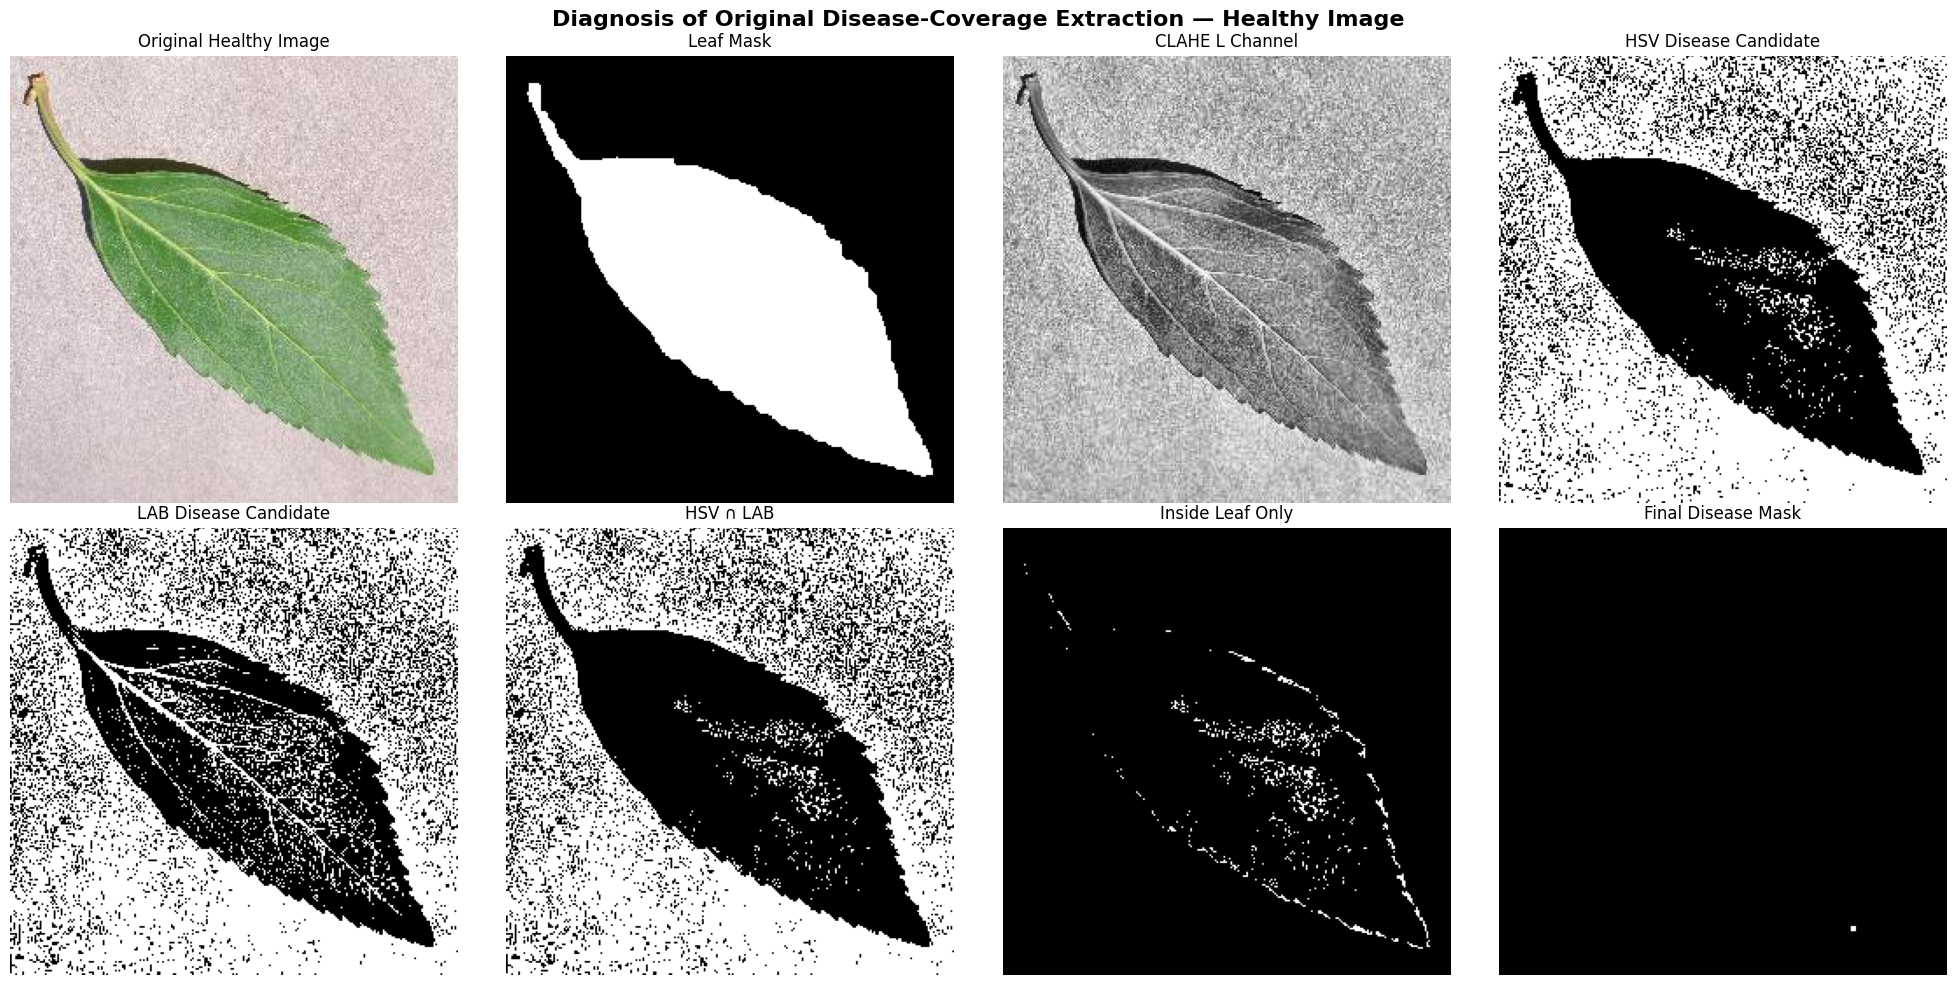

In [6]:
# ============================================================
# TASK 1 — DIAGNOSE ORIGINAL DISEASE-COVERAGE EXTRACTION
# NO CSV MODIFICATION
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Select ONE known healthy image
# ------------------------------------------------------------

healthy_sample = df[df["stage"] == "Healthy"].iloc[0]

image_path = healthy_sample["image_path"]

print("=" * 80)
print("ORIGINAL FEATURE EXTRACTION DIAGNOSTIC")
print("=" * 80)

print(f"Image path : {image_path}")
print(f"Stage      : {healthy_sample['stage']}")

# ------------------------------------------------------------
# Read image
# ------------------------------------------------------------

img = cv2.imread(image_path)

if img is None:
    raise ValueError(f"Could not read image: {image_path}")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# ------------------------------------------------------------
# STEP 1 — ORIGINAL LEAF MASK
# ------------------------------------------------------------

hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

lower_green = np.array([20, 25, 25])
upper_green = np.array([100, 255, 255])

leaf_mask = cv2.inRange(
    hsv,
    lower_green,
    upper_green
)

kernel = np.ones((7, 7), np.uint8)

leaf_mask = cv2.morphologyEx(
    leaf_mask,
    cv2.MORPH_CLOSE,
    kernel
)

leaf_pixel_count = cv2.countNonZero(leaf_mask)

# ------------------------------------------------------------
# STEP 2 — ORIGINAL CLAHE
# ------------------------------------------------------------

lab = cv2.cvtColor(
    img_rgb,
    cv2.COLOR_RGB2LAB
)

l_channel, a_channel, b_channel = cv2.split(lab)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

l_enhanced = clahe.apply(l_channel)

lab_enhanced = cv2.merge([
    l_enhanced,
    a_channel,
    b_channel
])

img_enhanced_rgb = cv2.cvtColor(
    lab_enhanced,
    cv2.COLOR_LAB2RGB
)

hsv_enhanced = cv2.cvtColor(
    img_enhanced_rgb,
    cv2.COLOR_RGB2HSV
)

# ------------------------------------------------------------
# STEP 3 — ORIGINAL HSV DISEASE MASK
# ------------------------------------------------------------

lower_disease_hsv = np.array([0, 0, 170])
upper_disease_hsv = np.array([180, 60, 255])

disease_mask_hsv = cv2.inRange(
    hsv_enhanced,
    lower_disease_hsv,
    upper_disease_hsv
)

# ------------------------------------------------------------
# STEP 4 — ORIGINAL LAB DISEASE MASK
# ------------------------------------------------------------

lower_disease_lab = np.array([170, 0, 0])
upper_disease_lab = np.array([255, 255, 255])

disease_mask_lab = cv2.inRange(
    lab_enhanced,
    lower_disease_lab,
    upper_disease_lab
)

# ------------------------------------------------------------
# STEP 5 — HSV AND LAB
# ------------------------------------------------------------

disease_mask_raw = cv2.bitwise_and(
    disease_mask_hsv,
    disease_mask_lab
)

# ------------------------------------------------------------
# STEP 6 — RESTRICT TO LEAF
# ------------------------------------------------------------

disease_mask_inside_leaf = cv2.bitwise_and(
    disease_mask_raw,
    leaf_mask
)

# ------------------------------------------------------------
# STEP 7 — MORPHOLOGICAL CLEANUP
# ------------------------------------------------------------

kernel_small = np.ones((3, 3), np.uint8)

disease_mask_final = cv2.morphologyEx(
    disease_mask_inside_leaf,
    cv2.MORPH_OPEN,
    kernel_small
)

disease_mask_final = cv2.morphologyEx(
    disease_mask_final,
    cv2.MORPH_CLOSE,
    kernel_small
)

# ------------------------------------------------------------
# COUNTS
# ------------------------------------------------------------

raw_hsv_pixels = cv2.countNonZero(disease_mask_hsv)
raw_lab_pixels = cv2.countNonZero(disease_mask_lab)
raw_combined_pixels = cv2.countNonZero(disease_mask_raw)
inside_leaf_pixels = cv2.countNonZero(disease_mask_inside_leaf)
final_disease_pixels = cv2.countNonZero(disease_mask_final)

coverage_raw = (
    raw_combined_pixels / leaf_pixel_count * 100
    if leaf_pixel_count > 0 else 0
)

coverage_inside_leaf = (
    inside_leaf_pixels / leaf_pixel_count * 100
    if leaf_pixel_count > 0 else 0
)

coverage_final = (
    final_disease_pixels / leaf_pixel_count * 100
    if leaf_pixel_count > 0 else 0
)

print()
print("=" * 80)
print("PIXEL-LEVEL DIAGNOSIS")
print("=" * 80)

print(f"Leaf pixels                     : {leaf_pixel_count:,}")
print(f"HSV candidate pixels            : {raw_hsv_pixels:,}")
print(f"LAB candidate pixels            : {raw_lab_pixels:,}")
print(f"HSV ∩ LAB pixels                : {raw_combined_pixels:,}")
print(f"HSV ∩ LAB pixels inside leaf    : {inside_leaf_pixels:,}")
print(f"Final disease pixels            : {final_disease_pixels:,}")

print()
print(f"Raw HSV+LAB / leaf coverage     : {coverage_raw:.2f}%")
print(f"Inside-leaf coverage            : {coverage_inside_leaf:.2f}%")
print(f"Final coverage                  : {coverage_final:.2f}%")

# ------------------------------------------------------------
# VISUALIZE EVERY STEP
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title("Original Healthy Image")

axes[0, 1].imshow(leaf_mask, cmap="gray")
axes[0, 1].set_title("Leaf Mask")

axes[0, 2].imshow(l_enhanced, cmap="gray")
axes[0, 2].set_title("CLAHE L Channel")

axes[0, 3].imshow(disease_mask_hsv, cmap="gray")
axes[0, 3].set_title("HSV Disease Candidate")

axes[1, 0].imshow(disease_mask_lab, cmap="gray")
axes[1, 0].set_title("LAB Disease Candidate")

axes[1, 1].imshow(disease_mask_raw, cmap="gray")
axes[1, 1].set_title("HSV ∩ LAB")

axes[1, 2].imshow(disease_mask_inside_leaf, cmap="gray")
axes[1, 2].set_title("Inside Leaf Only")

axes[1, 3].imshow(disease_mask_final, cmap="gray")
axes[1, 3].set_title("Final Disease Mask")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "Diagnosis of Original Disease-Coverage Extraction — Healthy Image",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [7]:
from google.colab import drive
drive.mount('/content/drive')

print("Google Drive connected.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected.


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# CHANGE THIS PATH
IMAGE_PATH = "/content/drive/MyDrive/your_image.jpg"

img_bgr = cv2.imread(IMAGE_PATH)

if img_bgr is None:
    raise FileNotFoundError(f"Could not load image: {IMAGE_PATH}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

print("Image shape:", img_rgb.shape)

plt.figure(figsize=(7, 5))
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Original Image")
plt.show()

FileNotFoundError: Could not load image: /content/drive/MyDrive/your_image.jpg

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import os

# Search your Google Drive for image files
image_extensions = (".jpg", ".jpeg", ".png")

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(image_extensions):
            if "cherry" in root.lower() or "cherry" in file.lower():
                matches.append(os.path.join(root, file))

print("Cherry images found:", len(matches))

for path in matches[:20]:
    print(path)

Cherry images found: 4397
/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/ebedbe48-ede7-49f1-beb0-6df1375f74d7___JR_HL 4117_180deg.JPG
/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/e8982035-5247-4ff7-838f-24a9455894af___JR_HL 4242_180deg.JPG
/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/ee929bdd-22bd-4a39-be24-11aa93d586fa___JR_HL 9576_flipTB.JPG
/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/e8a50fe1-fe8c-41cf-976f-6c59b6413a26___JR_HL 9553_180deg.JPG
/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/ead906bb-4bf6-4adf-b9c9-05248df3e776___JR_HL 9671_180deg.JPG
/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/eaf17e05-c2b7-4017-8553-1b11f0ba3941___JR_HL 4226_180deg.JPG
/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/ea04086e-125c-4836-b890-06d4c9afe236___JR_HL 9517.JPG
/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/e9608c30-5177-4a98-82b9-9acd685c6673___JR_

Image loaded successfully
Image shape: (256, 256, 3)


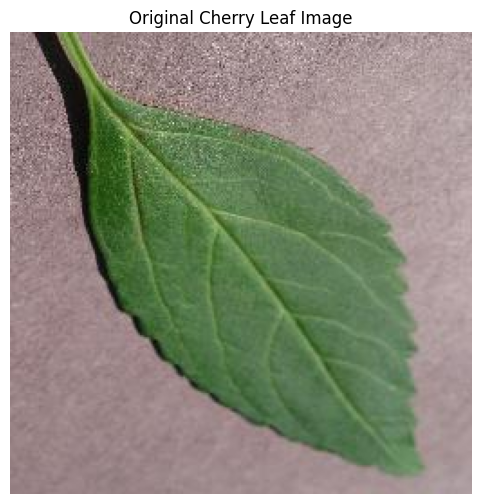

In [11]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

IMAGE_PATH = "/content/drive/MyDrive/Cherry/Cherry_(including_sour)___healthy/ebedbe48-ede7-49f1-beb0-6df1375f74d7___JR_HL 4117_180deg.JPG"

img_bgr = cv2.imread(IMAGE_PATH)

if img_bgr is None:
    raise FileNotFoundError(f"Could not load image: {IMAGE_PATH}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

print("Image loaded successfully")
print("Image shape:", img_rgb.shape)

plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Original Cherry Leaf Image")
plt.show()

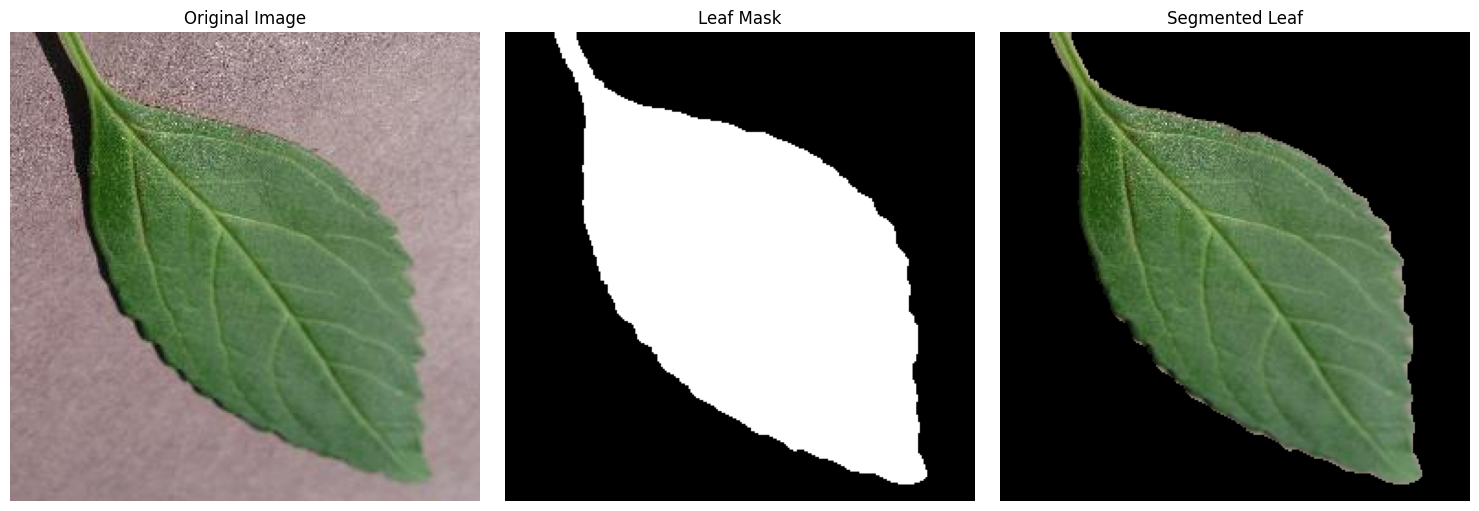

Leaf Pixels : 26527
Leaf Coverage : 40.48 %


In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Convert image to HSV
# ---------------------------------------------------------
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# ---------------------------------------------------------
# 2. Create initial green-leaf mask
# ---------------------------------------------------------
# Green hue range
lower_green = np.array([25, 25, 20])
upper_green = np.array([100, 255, 255])

leaf_mask = cv2.inRange(hsv, lower_green, upper_green)

# ---------------------------------------------------------
# 3. Morphological opening
#    Removes small isolated noise
# ---------------------------------------------------------
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

leaf_mask = cv2.morphologyEx(
    leaf_mask,
    cv2.MORPH_OPEN,
    kernel,
    iterations=1
)

# ---------------------------------------------------------
# 4. Morphological closing
#    Fills small gaps inside the leaf
# ---------------------------------------------------------
leaf_mask = cv2.morphologyEx(
    leaf_mask,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=3
)

# ---------------------------------------------------------
# 5. Keep only the largest connected component
# ---------------------------------------------------------
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    leaf_mask,
    connectivity=8
)

if num_labels > 1:

    # Ignore background (label 0)
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])

    leaf_mask = np.where(
        labels == largest_label,
        255,
        0
    ).astype(np.uint8)

# ---------------------------------------------------------
# 6. Fill remaining small holes
# ---------------------------------------------------------
contours, _ = cv2.findContours(
    leaf_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if contours:
    largest_contour = max(contours, key=cv2.contourArea)

    clean_mask = np.zeros_like(leaf_mask)

    cv2.drawContours(
        clean_mask,
        [largest_contour],
        -1,
        255,
        thickness=cv2.FILLED
    )

    leaf_mask = clean_mask

# ---------------------------------------------------------
# 7. Create segmented leaf
# ---------------------------------------------------------
leaf_segmented = cv2.bitwise_and(
    img_rgb,
    img_rgb,
    mask=leaf_mask
)

# ---------------------------------------------------------
# 8. Display results
# ---------------------------------------------------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(leaf_mask, cmap="gray")
plt.title("Leaf Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(leaf_segmented)
plt.title("Segmented Leaf")
plt.axis("off")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 9. Calculate leaf coverage
# ---------------------------------------------------------
leaf_pixels = np.count_nonzero(leaf_mask)

total_pixels = leaf_mask.shape[0] * leaf_mask.shape[1]

leaf_percentage = (leaf_pixels / total_pixels) * 100

print("Leaf Pixels :", leaf_pixels)
print("Leaf Coverage :", round(leaf_percentage, 2), "%")

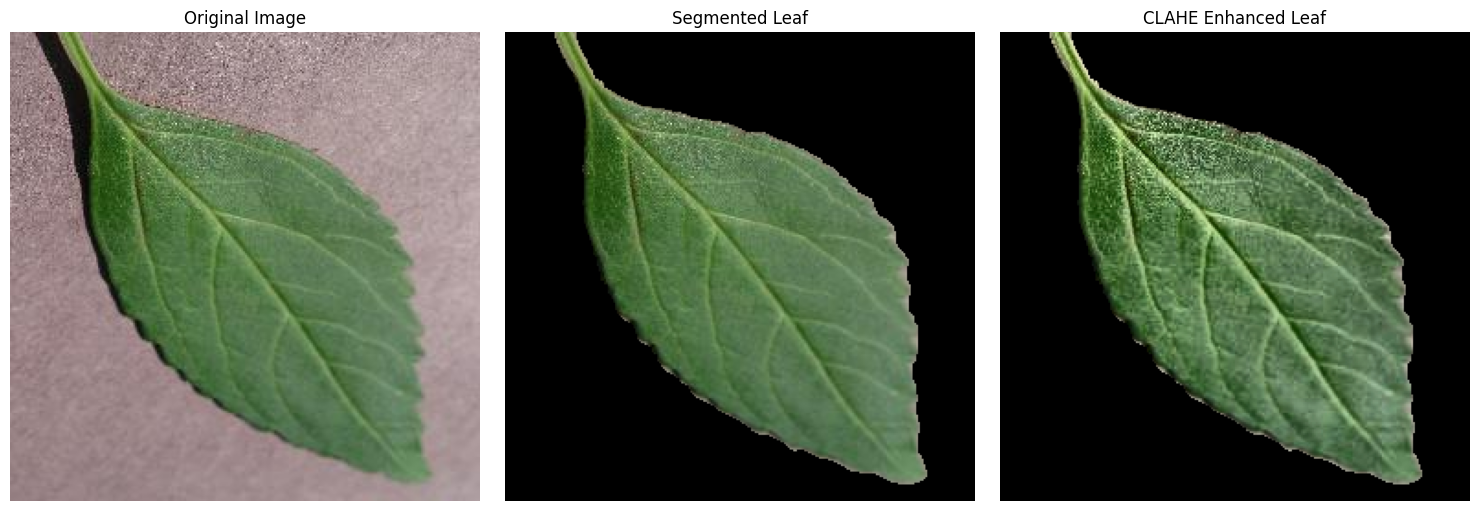

In [13]:
# ============================================================
# STEP 3: CONTRAST ENHANCEMENT USING CLAHE
# ============================================================

# Convert original image to LAB color space
lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

# Split LAB channels
L, A, B = cv2.split(lab)

# Create CLAHE object
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Apply CLAHE only to Luminance channel
L_enhanced = clahe.apply(L)

# Merge enhanced L with original A and B
lab_enhanced = cv2.merge([
    L_enhanced,
    A,
    B
])

# Convert back to RGB
enhanced_rgb = cv2.cvtColor(
    lab_enhanced,
    cv2.COLOR_LAB2RGB
)

# ------------------------------------------------------------
# Keep ONLY the segmented leaf
# ------------------------------------------------------------

enhanced_leaf = cv2.bitwise_and(
    enhanced_rgb,
    enhanced_rgb,
    mask=leaf_mask
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(leaf_segmented)
plt.title("Segmented Leaf")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(enhanced_leaf)
plt.title("CLAHE Enhanced Leaf")
plt.axis("off")

plt.tight_layout()
plt.show()

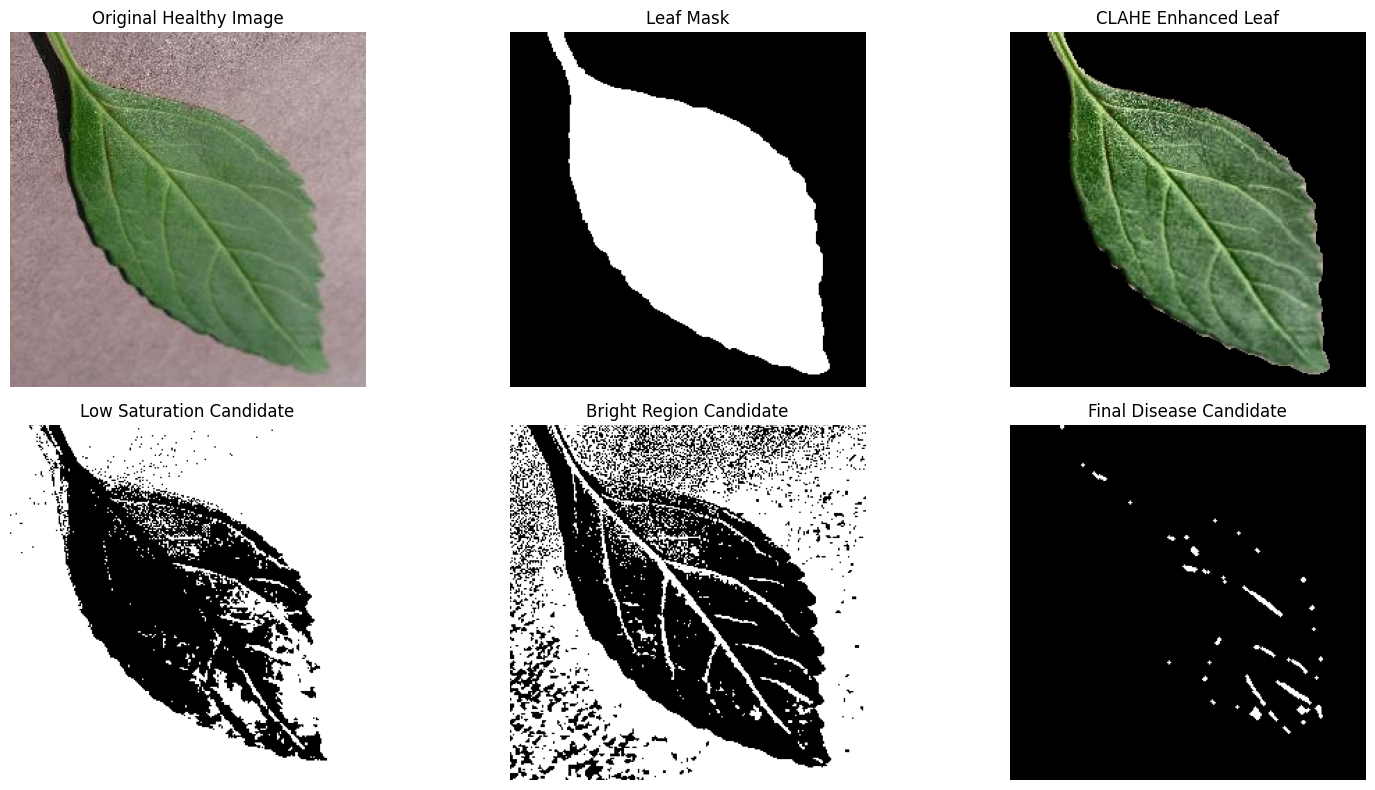

Leaf Pixels       : 26527
Disease Pixels    : 761
Disease Coverage  : 2.87 %


In [14]:
# ============================================================
# STEP 4: DISEASE CANDIDATE EXTRACTION
# ============================================================

# Work with the CLAHE-enhanced image
enhanced_bgr = cv2.cvtColor(enhanced_rgb, cv2.COLOR_RGB2BGR)

# Convert enhanced image to different color spaces
hsv_enhanced = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2HSV)
lab_enhanced = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2LAB)

# Extract channels
H, S, V = cv2.split(hsv_enhanced)
L2, A2, B2 = cv2.split(lab_enhanced)

# ------------------------------------------------------------
# Candidate 1: Low saturation regions
# ------------------------------------------------------------
# Powdery mildew tends to appear lighter/whitish than
# healthy green tissue, therefore saturation can decrease.
low_saturation = cv2.inRange(
    S,
    0,
    75
)

# ------------------------------------------------------------
# Candidate 2: Bright regions
# ------------------------------------------------------------
# Use V channel to identify relatively bright regions.
bright_regions = cv2.inRange(
    V,
    150,
    255
)

# ------------------------------------------------------------
# Combine candidates
# ------------------------------------------------------------
disease_candidate = cv2.bitwise_and(
    low_saturation,
    bright_regions
)

# ------------------------------------------------------------
# CRITICAL:
# Keep disease candidates ONLY inside the leaf
# ------------------------------------------------------------
disease_candidate = cv2.bitwise_and(
    disease_candidate,
    leaf_mask
)

# ------------------------------------------------------------
# Remove tiny isolated noise
# ------------------------------------------------------------
small_kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (3, 3)
)

disease_candidate = cv2.morphologyEx(
    disease_candidate,
    cv2.MORPH_OPEN,
    small_kernel,
    iterations=1
)

# ------------------------------------------------------------
# Close small gaps in candidate regions
# ------------------------------------------------------------
disease_candidate = cv2.morphologyEx(
    disease_candidate,
    cv2.MORPH_CLOSE,
    small_kernel,
    iterations=2
)

# ------------------------------------------------------------
# Display diagnostic results
# ------------------------------------------------------------

plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Healthy Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(leaf_mask, cmap="gray")
plt.title("Leaf Mask")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(enhanced_leaf)
plt.title("CLAHE Enhanced Leaf")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(low_saturation, cmap="gray")
plt.title("Low Saturation Candidate")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(bright_regions, cmap="gray")
plt.title("Bright Region Candidate")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(disease_candidate, cmap="gray")
plt.title("Final Disease Candidate")
plt.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Calculate candidate coverage
# ------------------------------------------------------------

leaf_pixels = np.count_nonzero(leaf_mask)
disease_pixels = np.count_nonzero(disease_candidate)

if leaf_pixels > 0:
    disease_coverage = (
        disease_pixels / leaf_pixels
    ) * 100
else:
    disease_coverage = 0

print("Leaf Pixels       :", leaf_pixels)
print("Disease Pixels    :", disease_pixels)
print("Disease Coverage  :", round(disease_coverage, 2), "%")